# Benchmark Level 1 multigrup: medium tak hingga (MCMR vs OpenMC vs analitik)

Medium homogen tak hingga (semua sisi reflektif), 2, 3, dan 7 grup, dengan matriks hamburan umum (`chi_scatter`, termasuk hamburan naik dan turun) dan spektrum fisi (`chi_fission`). Data yang sama dipakai di tiga tempat: solusi analitik, MCMR, dan OpenMC (mode multigrup). Yang dibandingkan: **k** dan **spektrum fluks per grup**.

**Solusi analitik** (matriks): `A φ = (1/k) F φ`, dengan `A = diag(Σt) − S`, `S[tujuan, asal] = Σs,asal · P[asal][tujuan]` (P = `chi_scatter` ternormalisasi per baris), dan `F = χ (νΣf)ᵀ` (rank-1). Maka `φ ∝ A⁻¹χ` dan `k = (νΣf)ᵀ A⁻¹ χ`.

**Konvensi:**
- Indeks grup 0 = grup pertama di OpenMC (energi tertinggi) dan di MCMR. Tally filter energi OpenMC berurutan menaik, jadi dibalik saat dibaca.
- Absorpsi OpenMC = Σt − Σs (tangkapan + fisi); di MCMR "sigma_a" hanya tangkapan.
- **Spektrum fluks:** tally fluks MCMR kumulatif sepanjang run (semua generasi, termasuk generasi 1 yang lahir dari sumber seragam antar grup). Agar sebanding, OpenMC dijalankan dengan `inactive = 0` sehingga tally fluksnya juga mencakup semua generasi. Di medium tak hingga sumber fisi langsung berspektrum χ mulai generasi 2, sehingga spektrum tally yang diharapkan dapat dihitung eksak: `∝ A⁻¹u + (n_gen−1)·A⁻¹χ` (u = sumber seragam). Nilai inilah yang dipakai sebagai "analitik" di tabel spektrum. Statistik k tetap membuang `n_skip` generasi awal saat analisis.
- Data kasus sintetis (bukan data nuklir sungguhan); 7G memakai matriks hamburan tridiagonal.

**Prasyarat:** `mcmr` versi terbaru terpasang (`pip install .`) dan OpenMC 0.16 (conda-forge) di environment yang sama.

## 1. Konfigurasi

In [1]:
import os
import numpy as np

# --- Kasus multigrup (satuan 1/cm; indeks grup 0-based, 0 = grup tercepat) ---
# chi_fission  : spektrum kelahiran neutron fisi (dinormalisasi otomatis)
# chi_scatter  : P[asal][tujuan], peluang tujuan hamburan (tiap baris dinormalisasi otomatis).
#                Laju hamburan tetap sigma_s[asal]; matriks hanya menentukan tujuannya.
def matriks_tridiagonal(G, stay=0.65, down=0.30, up=0.05):
    P = np.zeros((G, G))
    for g in range(G):
        P[g, g] += stay
        if g + 1 < G: P[g, g + 1] += down
        else:         P[g, g] += down      # grup terakhir: tidak ada tujuan lebih rendah
        if g - 1 >= 0: P[g, g - 1] += up
        else:          P[g, g] += up       # grup pertama: tidak ada tujuan lebih tinggi
    return P.round(6).tolist()

cases = {
    "2G": dict(sigma_t=[0.474, 1.23],
               sigma_s=[0.45, 1.10],
               sigma_f=[0.004, 0.08],
               nu=[2.5, 2.43],
               chi_fission=[0.99, 0.01],
               chi_scatter=[[0.80, 0.20],
                            [0.05, 0.95]]),
    "3G": dict(sigma_t=[0.423, 0.645, 1.138],
               sigma_s=[0.40, 0.60, 1.00],
               sigma_f=[0.003, 0.015, 0.078],
               nu=[2.8, 2.6, 2.43],
               chi_fission=[0.7, 0.3, 0.0],
               chi_scatter=[[0.60, 0.35, 0.05],
                            [0.02, 0.70, 0.28],
                            [0.00, 0.08, 0.92]]),
    "7G": dict(sigma_t=[0.2065, 0.2856, 0.3585, 0.4633, 0.6216, 0.8465, 1.236],
               sigma_s=[0.20, 0.28, 0.35, 0.45, 0.60, 0.80, 1.10],
               sigma_f=[0.0025, 0.0016, 0.0025, 0.0033, 0.0066, 0.0165, 0.076],
               nu=[2.85, 2.85, 2.8, 2.7, 2.6, 2.5, 2.43],
               chi_fission=[0.55, 0.30, 0.12, 0.03, 0.0, 0.0, 0.0],
               chi_scatter=matriks_tridiagonal(7)),
}

# --- Parameter simulasi ---
N         = 20000   # partikel per generasi
n_gen     = 220     # jumlah generasi per run
n_skip    = 20      # generasi awal yang dibuang (tidak dipakai di statistik)
N_run     = 5       # jumlah run independen per kode, per kasus
L         = 10.0    # sisi kotak (cm)
k_initial = 1.0     # k awal generasi 1 (hanya MCMR; OpenMC tidak punya opsi ini, memakai 1.0)

OUTPUT_DIR = "output_level1_mg"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Solusi analitik

In [2]:
import numpy as np
np.set_printoptions(precision=5, suppress=True)

def matriks_hamburan(c):
    """S[tujuan, asal] = sigma_s[asal] * P[asal][tujuan], P = chi_scatter ternormalisasi per baris."""
    P = np.array(c["chi_scatter"], float)
    sums = P.sum(axis=1, keepdims=True)
    P = np.divide(P, sums, out=np.zeros_like(P), where=sums > 0)
    return (np.array(c["sigma_s"], float)[:, None] * P).T

def solusi_analitik(c, n_gen=n_gen):
    sigma_t = np.array(c["sigma_t"], float)
    nu_sf   = np.array(c["nu"], float) * np.array(c["sigma_f"], float)
    chi     = np.array(c["chi_fission"], float); chi = chi / chi.sum()
    S = matriks_hamburan(c)
    A = np.diag(sigma_t) - S                 # operator removal
    x = np.linalg.solve(A, chi)              # A x = chi
    k = nu_sf @ x                            # k = (nu Sigma_f)^T A^-1 chi
    # Spektrum yang akan terukur oleh tally kumulatif (semua n_gen generasi): generasi 1 lahir dari sumber
    # seragam antar grup (u), generasi 2+ lahir dari spektrum fisi chi (sumber fisi langsung = chi di medium
    # tak hingga). Jejak per riwayat: A^-1 u untuk generasi 1 dan A^-1 chi untuk n_gen-1 generasi sisanya.
    G = len(sigma_t); u = np.ones(G) / G
    tally = np.linalg.solve(A, u) + (n_gen - 1) * x
    return dict(k=k, phi=x / x.sum(), phi_tally=tally / tally.sum(), A=A, S=S, chi=chi, nu_sf=nu_sf)

analitik = {name: solusi_analitik(c) for name, c in cases.items()}
for name, a in analitik.items():
    print(f"[{name}] k-inf analitik = {a['k']:.5f}")
    print("  A = T - S =\n", a["A"] if len(a["A"]) <= 3 else "(matriks 7x7, tidak ditampilkan)")
    print("  spektrum fluks kesetimbangan phi    =", a["phi"])
    print(f"  spektrum fluks tally ({n_gen} generasi)  =", a["phi_tally"], "(termasuk generasi 1)")
    print("  spektrum sumber fisi  nuSf*phi/jumlah =", a["nu_sf"] * a["phi"] / (a["nu_sf"] @ a["phi"]))

[2G] k-inf analitik = 1.20072
  A = T - S =
 [[ 0.114 -0.055]
 [-0.09   0.185]]
  spektrum fluks kesetimbangan phi    = [0.67058 0.32942]
  spektrum fluks tally (220 generasi)  = [0.67011 0.32989] (termasuk generasi 1)
  spektrum sumber fisi  nuSf*phi/jumlah = [0.09479 0.90521]
[3G] k-inf analitik = 1.14807
  A = T - S =
 [[ 0.183 -0.012  0.   ]
 [-0.14   0.225 -0.08 ]
 [-0.02  -0.168  0.218]]
  spektrum fluks kesetimbangan phi    = [0.28866 0.38679 0.32456]
  spektrum fluks tally (220 generasi)  = [0.28822 0.38678 0.32499] (termasuk generasi 1)
  spektrum sumber fisi  nuSf*phi/jumlah = [0.03068 0.19088 0.77843]
[7G] k-inf analitik = 1.09853
  A = T - S =
 (matriks 7x7, tidak ditampilkan)
  spektrum fluks kesetimbangan phi    = [0.22538 0.22443 0.18669 0.13417 0.08895 0.06221 0.07817]
  spektrum fluks tally (220 generasi)  = [0.22509 0.22422 0.18661 0.13422 0.08907 0.06236 0.07843] (termasuk generasi 1)
  spektrum sumber fisi  nuSf*phi/jumlah = [0.06787 0.04326 0.05523 0.05053 0.06452 

## 3. MCMR

### 3.1 Geometri MCMR

/home/azma/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


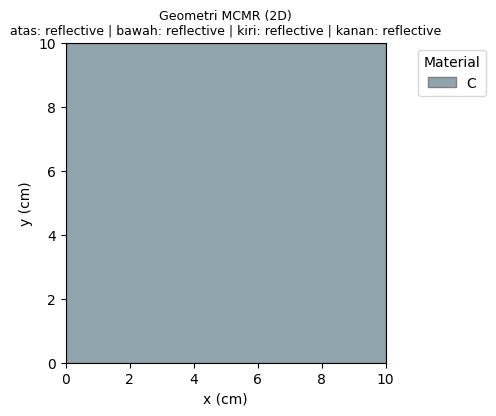

In [3]:
import io, sys, csv, shutil, subprocess, tempfile, re, warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import mcmr

MATERIAL = "C"   # nama material hanya label; datanya dari library

world = mcmr.World(x_world=L, y_world=L, x_grid=[], y_grid=[],
                   material_matrix=[[MATERIAL]], sources=[[1]],
                   bc_top="reflective", bc_bot="reflective",
                   bc_left="reflective", bc_right="reflective")

def plot_mcmr_geometry(w, ax):
    colors = {"Fe": "#cfd8dc", "Pb": "#bcaaa4", "C": "#90a4ae", "Be": "#c8e6c9"}
    xe = [0.0] + list(w.x_grid) + [w.x_world]
    ye = [0.0] + list(w.y_grid) + [w.y_world]
    ny = len(ye) - 1
    used = {}
    for row in range(ny):                       # row 0 = baris paling atas
        for col in range(len(xe) - 1):
            m = w.material_matrix[row][col]; iy = ny - 1 - row
            ax.add_patch(Rectangle((xe[col], ye[iy]), xe[col+1]-xe[col], ye[iy+1]-ye[iy],
                                   facecolor=colors.get(m, "#dddddd"), edgecolor="gray"))
            used[m] = colors.get(m, "#dddddd")
    for c in w.circles:
        ax.add_patch(Circle((c["cx"], c["cy"]), c["r"], facecolor=colors.get(c["material"], "#dddddd"),
                            edgecolor="black"))
        used[c["material"]] = colors.get(c["material"], "#dddddd")
    ax.set_xlim(0, w.x_world); ax.set_ylim(0, w.y_world); ax.set_aspect("equal")
    ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)")
    ax.set_title(f"Geometri MCMR (2D)\natas: {w.bc_top} | bawah: {w.bc_bot} | kiri: {w.bc_left} | kanan: {w.bc_right}", fontsize=9)
    ax.legend(handles=[Rectangle((0,0),1,1,facecolor=c,edgecolor="gray",label=m) for m,c in used.items()],
              loc="upper left", bbox_to_anchor=(1.08, 1.0), title="Material")

fig, ax = plt.subplots(figsize=(5, 5))
plot_mcmr_geometry(world, ax)
plt.tight_layout(); plt.show()

### 3.2 Jalankan MCMR

In [4]:
class _MCMRProgress:
    """Meneruskan baris progress MCMR dengan awalan 'Kasus .. | Run ..'.
    Banner awal dan ringkasan akhir (yang memuat k) tidak ditampilkan."""
    def __init__(self, real, prefix):
        self.real, self.prefix = real, prefix
    def write(self, s):
        if s.startswith("\rGen"):
            return self.real.write("\r" + self.prefix + s[1:])
        if "died" in s:
            return self.real.write(s)
        return len(s)
    def flush(self): self.real.flush()
    def __getattr__(self, name): return getattr(self.real, name)

mcmr_rows, mcmr_flux_rows = [], []     # k per generasi; spektrum fluks per grup
for ci, (name, c) in enumerate(cases.items(), 1):
    lib = mcmr.MaterialLibrary().add_material(MATERIAL, c["sigma_t"], c["sigma_s"],
                                              c["sigma_f"], c["nu"], c["chi_fission"], c["chi_scatter"])
    for run in range(1, N_run + 1):
        real = sys.stdout
        sys.stdout = _MCMRProgress(real, f"Kasus {ci}/{len(cases)} ({name}) | Run {run}/{N_run} | ")
        try:
            sim = world.run(N=N, mode="group", group_materials=lib, n_gen=n_gen,
                            max_save=0, resolution=1, k=k_initial, seed=1000 * ci + run)
        finally:
            sys.stdout = real
        tally = sim.get_tally()
        mcmr_rows += [(name, run, g + 1, float(k)) for g, k in enumerate(tally.k_estimate)]
        flux_g = np.array(tally.flux_tally).reshape(tally.flux_groups, -1).sum(axis=1)   # jumlah semua sel, per grup
        flux_g = flux_g / flux_g.sum()
        mcmr_flux_rows += [(name, run, g, float(f)) for g, f in enumerate(flux_g)]
print(f"\nMCMR selesai: {len(cases)} kasus x {N_run} run x {n_gen} generasi")

mcmr_csv = os.path.join(OUTPUT_DIR, "k_mcmr_per_generation.csv")
with open(mcmr_csv, "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["case", "run", "generation", "k"]); wr.writerows(mcmr_rows)
mcmr_flux_csv = os.path.join(OUTPUT_DIR, "flux_spectrum_mcmr.csv")
with open(mcmr_flux_csv, "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["case", "run", "group", "flux_normalized"]); wr.writerows(mcmr_flux_rows)
print("Disimpan:", mcmr_csv, f"({len(mcmr_rows)} baris),", mcmr_flux_csv, f"({len(mcmr_flux_rows)} baris)")

Kasus 3/3 (7G) | Run 5/5 | Gen 220/220 | Particle: [20000/20000] (100%) | Fission bank: 19936      
MCMR selesai: 3 kasus x 5 run x 220 generasi
Disimpan: output_level1_mg/k_mcmr_per_generation.csv (3300 baris), output_level1_mg/flux_spectrum_mcmr.csv (60 baris)


## 4. OpenMC

`inactive = 0` dan statepoint ditulis di setiap batch, sehingga nilai collision, tracklength, dan absorption per generasi bisa diperoleh dari selisih global tally kumulatif (pembuangan `n_skip` dilakukan saat analisis, sama seperti MCMR). Dengan `inactive = 0`, tally fluks per grup juga mencakup semua generasi, seperti tally fluks MCMR.

In [5]:
import openmc, openmc.mgxs
warnings.filterwarnings("ignore")

def build_openmc_model(wd, c, seed=1):
    """Tulis semua input OpenMC (multigrup) untuk satu kasus ke folder wd."""
    sigma_t = np.array(c["sigma_t"], float); sigma_s = np.array(c["sigma_s"], float)
    nu_sf = np.array(c["nu"], float) * np.array(c["sigma_f"], float)
    chi = np.array(c["chi_fission"], float); chi = chi / chi.sum()
    G = len(sigma_t)
    edges = np.logspace(-3, 7.3, G + 1)               # eV, menaik; grup 0 OpenMC = bin tertinggi
    S_from_to = matriks_hamburan(c).T                  # OpenMC: [asal][tujuan]

    groups = openmc.mgxs.EnergyGroups(edges)
    x = openmc.XSdata('mat', groups); x.order = 0
    x.set_total(sigma_t); x.set_absorption(sigma_t - sigma_s)   # absorpsi = tangkapan + fisi
    x.set_scatter_matrix(S_from_to[:, :, None])
    x.set_nu_fission(nu_sf); x.set_chi(chi)
    mg = openmc.MGXSLibrary(groups); mg.add_xsdata(x)
    mgxs_path = os.path.join(wd, 'mgxs.h5'); mg.export_to_hdf5(mgxs_path)

    mat = openmc.Material(name='mat'); mat.set_density('macro', 1.0); mat.add_macroscopic('mat')
    mats = openmc.Materials([mat]); mats.cross_sections = mgxs_path

    px0, px1 = openmc.XPlane(0, boundary_type='reflective'), openmc.XPlane(L, boundary_type='reflective')
    py0, py1 = openmc.YPlane(0, boundary_type='reflective'), openmc.YPlane(L, boundary_type='reflective')
    pz0, pz1 = openmc.ZPlane(0, boundary_type='reflective'), openmc.ZPlane(L, boundary_type='reflective')
    cell = openmc.Cell(name='kotak', fill=mat, region=+px0 & -px1 & +py0 & -py1 & +pz0 & -pz1)
    geom = openmc.Geometry([cell])

    # sumber awal: seragam di ruang dan di antara grup (sama dengan MCMR)
    e_mid = np.sqrt(edges[:-1] * edges[1:])
    s = openmc.Settings()
    s.energy_mode = 'multi-group'; s.run_mode = 'eigenvalue'
    s.particles = N; s.batches = n_gen; s.inactive = 0; s.seed = seed
    s.source = openmc.IndependentSource(space=openmc.stats.Box((0, 0, 0), (L, L, L)),
                                        energy=openmc.stats.Discrete(e_mid, np.ones(G) / G))
    s.statepoint = {'batches': list(range(1, n_gen + 1))}
    s.sourcepoint = {'write': False}
    s.output = {'tallies': False}

    tal = openmc.Tally(name='flux_spectrum')
    tal.filters = [openmc.EnergyFilter(edges)]; tal.scores = ['flux']

    mats.export_to_xml(os.path.join(wd, 'materials.xml'))
    geom.export_to_xml(os.path.join(wd, 'geometry.xml'))
    s.export_to_xml(os.path.join(wd, 'settings.xml'))
    openmc.Tallies([tal]).export_to_xml(os.path.join(wd, 'tallies.xml'))
    return openmc.Model(geometry=geom, materials=mats, settings=s)

### 4.1 Geometri OpenMC

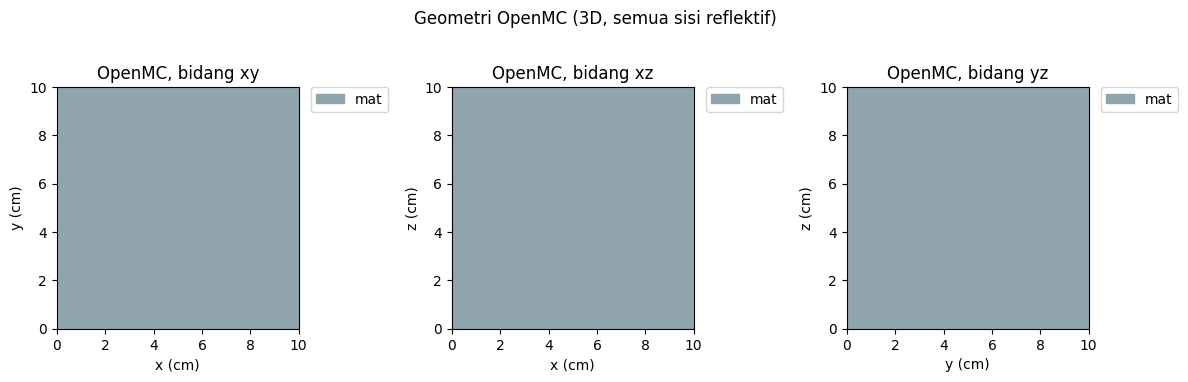

In [6]:
wd_plot = tempfile.mkdtemp(prefix="omc_geom_")
model_plot = build_openmc_model(wd_plot, next(iter(cases.values())))
openmc.config['mg_cross_sections'] = os.path.join(wd_plot, 'mgxs.h5')   # dibutuhkan untuk plot geometri mode multigrup

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, basis, (xl, yl) in zip(axes, ("xy", "xz", "yz"), (("x", "y"), ("x", "z"), ("y", "z"))):
    model_plot.geometry.root_universe.plot(origin=(L/2, L/2, L/2), width=(L, L), basis=basis,
                                           color_by='material', axes=ax,
                                           colors={model_plot.materials[0]: (144, 164, 174)}, legend=True)
    ax.set_title(f"OpenMC, bidang {basis}"); ax.set_xlabel(f"{xl} (cm)"); ax.set_ylabel(f"{yl} (cm)")
fig.suptitle("Geometri OpenMC (3D, semua sisi reflektif)")
plt.tight_layout(); plt.show()
shutil.rmtree(wd_plot, ignore_errors=True)

### 4.2 Jalankan OpenMC

In [7]:
_batch_re = re.compile(r'^\s*(\d+)/1\s')

def run_openmc(name, c, ci, seed, run_idx):
    wd = tempfile.mkdtemp(prefix=f"omc_{name}_run{run_idx}_")
    try:
        build_openmc_model(wd, c, seed)
        proc = subprocess.Popen(["openmc"], cwd=wd, stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, text=True, bufsize=1)
        tail = []
        for line in proc.stdout:
            tail = (tail + [line.rstrip()])[-15:]
            m = _batch_re.match(line)
            if m:
                b = int(m.group(1))
                sys.stdout.write(f"\rKasus {ci}/{len(cases)} ({name}) | Run {run_idx}/{N_run} | "
                                 f"Batch {b}/{n_gen} ({100*b//n_gen}%) | Partikel/batch: {N}   ")
                sys.stdout.flush()
        if proc.wait() != 0:
            raise RuntimeError("OpenMC gagal:\n" + "\n".join(tail))

        w = len(str(n_gen))
        names = ("k-collision", "k-absorption", "k-tracklength")
        with openmc.StatePoint(os.path.join(wd, f"statepoint.{n_gen:0{w}d}.h5"), autolink=False) as sp:
            flux = sp.get_tally(name='flux_spectrum').mean.reshape(-1)[::-1]   # balik: indeks 0 = grup pertama
            flux = flux / flux.sum()
        rows = []
        prev = {n: 0.0 for n in names}
        for b in range(1, n_gen + 1):
            with openmc.StatePoint(os.path.join(wd, f"statepoint.{b:0{w}d}.h5"), autolink=False) as sp:
                gt = {r['name'].decode().strip(): float(r['sum']) for r in sp.global_tallies}
            cur = {n: gt[n] - prev[n] for n in names}; prev = {n: gt[n] for n in names}
            rows.append((name, run_idx, seed, b, cur["k-collision"], cur["k-tracklength"], cur["k-absorption"]))
        return rows, [(name, run_idx, g, float(f)) for g, f in enumerate(flux)]
    finally:
        shutil.rmtree(wd, ignore_errors=True)

omc_rows, flux_rows = [], []   # k per generasi; spektrum fluks per grup
for ci, (name, c) in enumerate(cases.items(), 1):
    for run in range(1, N_run + 1):
        r, f = run_openmc(name, c, ci, seed=1000 * ci + run, run_idx=run)
        omc_rows += r; flux_rows += f
print(f"\nOpenMC selesai: {len(cases)} kasus x {N_run} run x {n_gen} generasi")

omc_csv = os.path.join(OUTPUT_DIR, "k_openmc_per_generation.csv")
with open(omc_csv, "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["case", "run", "seed", "generation", "k_collision", "k_tracklength", "k_absorption"])
    wr.writerows(omc_rows)
flux_csv = os.path.join(OUTPUT_DIR, "flux_spectrum_openmc.csv")
with open(flux_csv, "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["case", "run", "group", "flux_normalized"]); wr.writerows(flux_rows)
print("Disimpan:", omc_csv, f"({len(omc_rows)} baris),", flux_csv, f"({len(flux_rows)} baris)")

Kasus 3/3 (7G) | Run 5/5 | Batch 220/220 (100%) | Partikel/batch: 20000   
OpenMC selesai: 3 kasus x 5 run x 220 generasi
Disimpan: output_level1_mg/k_openmc_per_generation.csv (3300 baris), output_level1_mg/flux_spectrum_openmc.csv (60 baris)


## 5. Perbandingan (dibaca dari file keluaran)


=== Kasus 2G (2 grup) ===
k analitik          = 1.20072
MCMR                = 1.20066 +- 0.00018  (-6 pcm)   z(vs analitik) = -0.33
OpenMC collision   = 1.20090 +- 0.00019  (+18 pcm)   z(MCMR-OpenMC) = -0.90
OpenMC tracklength = 1.20089 +- 0.00012  (+17 pcm)   z(MCMR-OpenMC) = -1.04
spektrum fluks (ternormalisasi, +- galat standar antar run)
  (kolom analitik = spektrum tally yang diharapkan untuk n_gen generasi, termasuk generasi 1)
  grup | analitik |      OpenMC       |       MCMR        | MCMR-OpenMC (%) | z(MCMR-OpenMC)
     0 | 0.67011  | 0.67009 +- 0.00002 | 0.67027 +- 0.00011 |   +0.026        | +1.49
     1 | 0.32989  | 0.32991 +- 0.00002 | 0.32973 +- 0.00011 |   -0.052        | -1.49

=== Kasus 3G (3 grup) ===
k analitik          = 1.14807
MCMR                = 1.14780 +- 0.00023  (-28 pcm)   z(vs analitik) = -1.23
OpenMC collision   = 1.14808 +- 0.00021  (+0 pcm)   z(MCMR-OpenMC) = -0.91
OpenMC tracklength = 1.14811 +- 0.00027  (+3 pcm)   z(MCMR-OpenMC) = -0.88
spektrum flu

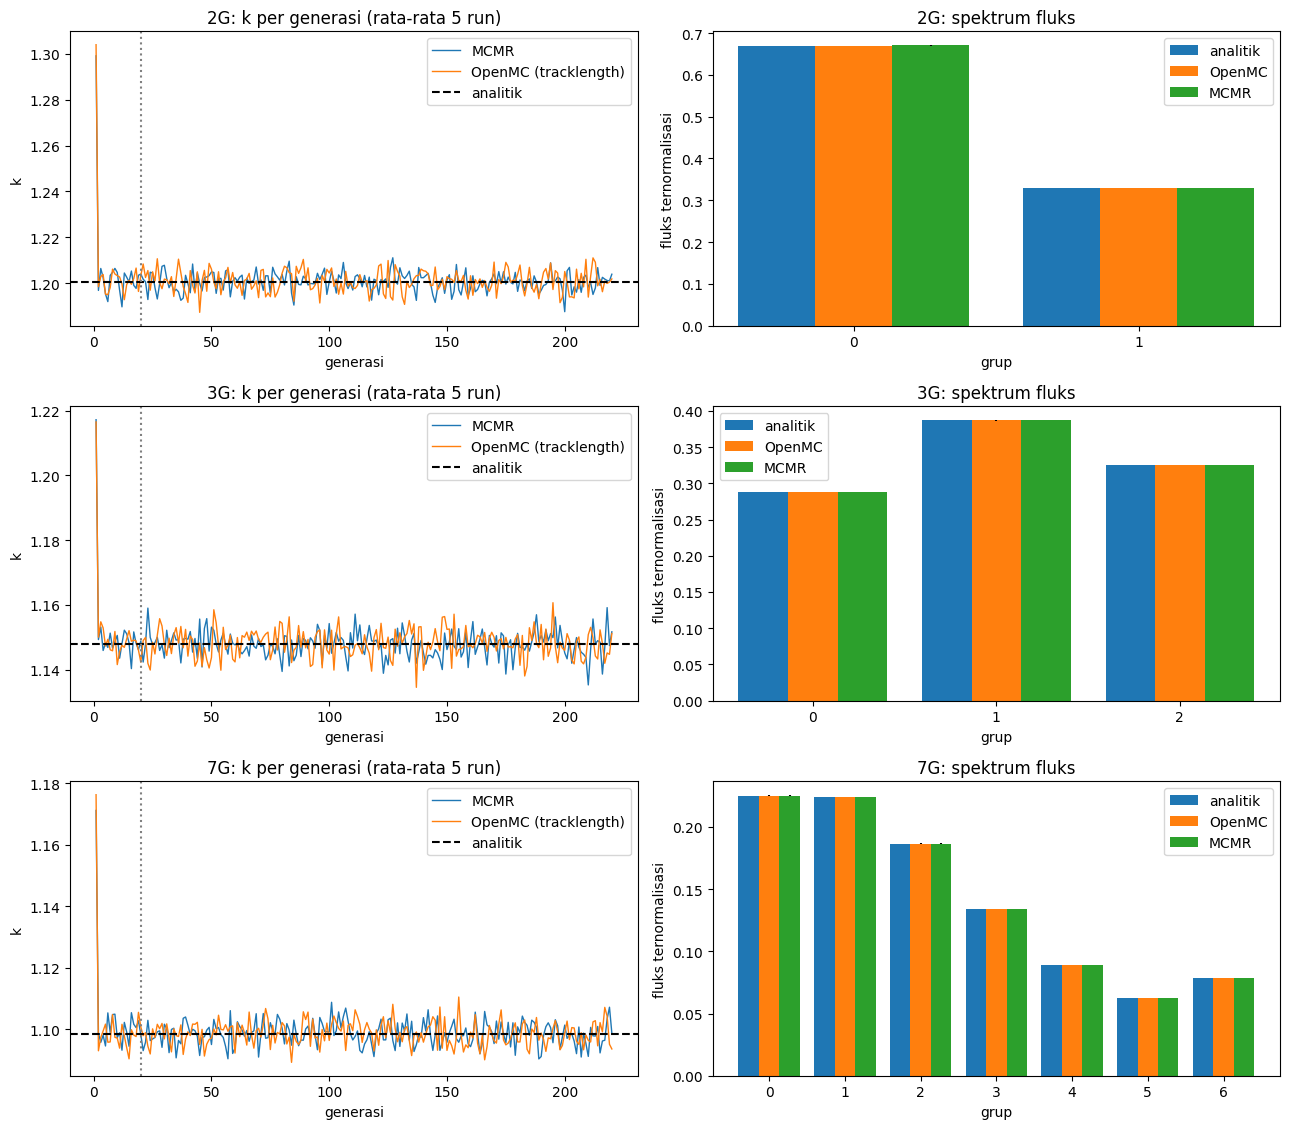

In [10]:
def read_csv(path):
    with open(path) as f:
        return list(csv.DictReader(f))

mm_rows = read_csv(mcmr_csv);  om_rows = read_csv(omc_csv)
fm_rows = read_csv(mcmr_flux_csv);  fo_rows = read_csv(flux_csv)

def per_run_means(rows, case, key):
    return np.array([np.mean([float(x[key]) for x in rows if x["case"] == case and int(x["run"]) == r
                              and int(x["generation"]) > n_skip]) for r in range(1, N_run + 1)])

def flux_matrix(rows, case, G):
    return np.array([[float(x["flux_normalized"]) for x in rows if x["case"] == case and int(x["run"]) == r]
                     for r in range(1, N_run + 1)])

for name, c in cases.items():
    ka = analitik[name]["k"]; G = len(c["sigma_t"])
    mm = per_run_means(mm_rows, name, "k"); e_m = mm.std(ddof=1) / np.sqrt(N_run)
    print(f"\n=== Kasus {name} ({G} grup) ===")
    print(f"k analitik          = {ka:.5f}")
    print(f"MCMR                = {mm.mean():.5f} +- {e_m:.5f}  ({(mm.mean()-ka)*1e5:+.0f} pcm)   z(vs analitik) = {(mm.mean()-ka)/e_m:+.2f}")
    for lab, key in (("collision", "k_collision"), ("tracklength", "k_tracklength")):
        v = per_run_means(om_rows, name, key); e = v.std(ddof=1) / np.sqrt(N_run)
        z = (mm.mean() - v.mean()) / np.hypot(e_m, e)
        print(f"OpenMC {lab:11s} = {v.mean():.5f} +- {e:.5f}  ({(v.mean()-ka)*1e5:+.0f} pcm)   z(MCMR-OpenMC) = {z:+.2f}")

    fm, fo = flux_matrix(fm_rows, name, G), flux_matrix(fo_rows, name, G)
    em, eo = fm.std(axis=0, ddof=1) / np.sqrt(N_run), fo.std(axis=0, ddof=1) / np.sqrt(N_run)
    print("spektrum fluks (ternormalisasi, +- galat standar antar run)")
    print("  (kolom analitik = spektrum tally yang diharapkan untuk n_gen generasi, termasuk generasi 1)")
    print("  grup | analitik |      OpenMC       |       MCMR        | MCMR-OpenMC (%) | z(MCMR-OpenMC)")
    for g in range(G):
        d = fm[:, g].mean() - fo[:, g].mean(); z = d / np.hypot(em[g], eo[g])
        print(f"  {g:4d} | {analitik[name]['phi_tally'][g]:.5f}  | {fo[:, g].mean():.5f} +- {eo[g]:.5f} | {fm[:, g].mean():.5f} +- {em[g]:.5f} |"
              f" {100*d/fo[:, g].mean():+8.3f}        | {z:+.2f}")

fig, axes = plt.subplots(len(cases), 2, figsize=(13, 3.8 * len(cases)), squeeze=False)
gens = np.arange(1, n_gen + 1)
for i, (name, c) in enumerate(cases.items()):
    G = len(c["sigma_t"]); idx = np.arange(G)
    ax = axes[i, 0]
    mk = np.mean([[float(x["k"]) for x in mm_rows if x["case"] == name and int(x["run"]) == r] for r in range(1, N_run + 1)], axis=0)
    ok = np.mean([[float(x["k_tracklength"]) for x in om_rows if x["case"] == name and int(x["run"]) == r] for r in range(1, N_run + 1)], axis=0)
    ax.plot(gens, mk, lw=1, label="MCMR"); ax.plot(gens, ok, lw=1, label="OpenMC (tracklength)")
    ax.axhline(analitik[name]["k"], color="k", ls="--", label="analitik"); ax.axvline(n_skip, color="gray", ls=":")
    ax.set_title(f"{name}: k per generasi (rata-rata {N_run} run)"); ax.set_xlabel("generasi"); ax.set_ylabel("k"); ax.legend()
    ax = axes[i, 1]
    fm, fo = flux_matrix(fm_rows, name, G), flux_matrix(fo_rows, name, G)
    ax.bar(idx - 0.27, analitik[name]["phi_tally"], 0.27, label="analitik")
    ax.bar(idx,        fo.mean(axis=0), 0.27, yerr=fo.std(axis=0, ddof=1), label="OpenMC")
    ax.bar(idx + 0.27, fm.mean(axis=0), 0.27, yerr=fm.std(axis=0, ddof=1), label="MCMR")
    ax.set_xticks(idx); ax.set_xlabel("grup"); ax.set_ylabel("fluks ternormalisasi"); ax.set_title(f"{name}: spektrum fluks"); ax.legend()
plt.tight_layout(); plt.show()